# Are newly-rural proposals actually trading away grid access?

Two things are separately established: `dc_proposal_rural_shift.ipynb` shows new data-
center proposals have gotten more rural since 2024. `dc_tier_composition.ipynb`
shows that, across the whole national ZIP population, rural ZIPs (low tier) sit far
from the power grid on average, and urban ZIPs (high tier) sit close to it -- a real
trade-off.

The tempting next sentence is "so the newly-rural pipeline is trading grid access for
cheaper/available land." That does NOT follow automatically -- it assumes the specific
sites getting proposed follow the same rural-vs-grid trade-off as the general ZIP
population. This notebook checks that directly instead of asserting it.

**Extraction fixed to match `dc_proposal_rural_shift.ipynb`'s correction**: earliest
dated forward-status EVENT from a record's full history, not gated on current status
(a proposal since built or cancelled is still a real historical proposal event). 552
matched records instead of 485.

**Rural definition corrected 2026-08-31** to USDA ERS's real RUCA codes (see
`dc_risk_divide.ipynb` for the concordance check against the old density proxy). One
real consequence on THIS notebook's own join: the rural-share-over-time trend no
longer clears conventional significance here (was p=0.0006 under the old proxy, is
p=0.11 under RUCA) -- real, checked three ways. The core finding this notebook exists
to check -- tier and grid access stay flat regardless -- is unaffected either way.

In [1]:
import json, re, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict

sys.path.insert(0, str(Path("../../merascope/notebooks").resolve()))
import dcmodel as D

CA_PATH = Path("../../merascope/notebooks/cache/labels/ca_facilities.json").resolve()
recs = json.loads(CA_PATH.read_text())
FORWARD = {"proposed", "permitted", "under_construction"}


def earliest_forward_date(rec):
    """Earliest dated forward-status event from the FULL statusHistory, regardless of
    current status -- see dc_proposal_rural_shift.ipynb for why this matters."""
    dates = [h.get("date") for h in (rec.get("statusHistory") or [])
             if h.get("status") in FORWARD and h.get("date")]
    norm = []
    for d in dates:
        m = re.match(r"^(\d{4})(-(\d{2}))?", d)
        if m:
            norm.append(f"{m.group(1)}-{m.group(3) or '01'}")
    return min(norm) if norm else None


rows = []
for r in recs:
    d = earliest_forward_date(r)
    if not d:
        continue
    loc = r.get("location") or {}
    if loc.get("lat") is None:
        continue
    rows.append({"id": r["id"], "date": d, "lat": loc["lat"], "lon": loc["lon"]})

gdf_pts = gpd.GeoDataFrame(rows, geometry=gpd.points_from_xy([r["lon"] for r in rows],
                                                              [r["lat"] for r in rows]),
                           crs="EPSG:4326")
print(f"{len(gdf_pts)} dated forward-looking records with real lat/lon")

566 dated forward-looking records with real lat/lon


In [2]:
# Recompute the same out-of-fold tier as the other two notebooks -- not reused, so
# this notebook stands alone and can't silently drift from a stale cached score.
df = D.load_model_table()
cols = [c for c in D.URBAN + D.POWER + D.PHYSICAL if c in df.columns]
blocks = D.spatial_blocks(df)
X = D.feature_matrix(df, cols).to_numpy()
y = df["has_dc"].to_numpy()
clf = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.06, max_leaf_nodes=15,
                                       l2_regularization=1.0, random_state=0)
p = cross_val_predict(clf, X, y, cv=GroupKFold(n_splits=8), groups=blocks,
                       method="predict_proba")[:, 1]
df["tier"] = pd.qcut(p.argsort().argsort(), 10, labels=False) + 1

zctas = D.load_zctas(verbose=False)
zctas = zctas.merge(df[["zcta", "tier"]], on="zcta", how="left")
join_cols = ["zcta", "tier", "tx_score_nat", "substation_score_nat",
             "contamination_score_nat", "pop_exposure_score_nat", "geometry"]
j = gpd.sjoin(gdf_pts, zctas[join_cols], how="inner", predicate="within")
j["year"] = j["date"].str[:4].astype(int)

ruca = pd.read_csv("../../merascope/notebooks/cache/labels/zcta_ruca_rural.csv",
                    dtype={"zcta": str})
j = j.merge(ruca[["zcta", "ruca_rural"]], on="zcta", how="left")
j["rural"] = j["ruca_rural"].fillna(False)  # USDA ERS RUCA, not the density proxy
print(f"{len(j)}/{len(gdf_pts)} matched to a real ZCTA with known tier + grid scores")

ERROR 1: PROJ: proj_create_from_database: Open of /home/simonhans/anaconda3/envs/merascope/share/proj failed


552/566 matched to a real ZCTA with known tier + grid scores


## The direct check

If newly-rural proposals were trading away grid access, the mean tier and mean grid-
access score of the dated pipeline should DROP as the years get more recent -- the same
years `dc_proposal_rural_shift.ipynb` shows going more rural.

In [3]:
periods = [(0, 2023, "pre-2024"), (2024, 2024, "2024"), (2025, 2025, "2025"), (2026, 9999, "2026")]
period_rows = []
for lo, hi, label in periods:
    g = j[(j["year"] >= lo) & (j["year"] <= hi)]
    period_rows.append({"period": label, "n": len(g), "mean_tier": g["tier"].mean(),
                        "mean_tx_score": g["tx_score_nat"].mean(),
                        "mean_substation_score": g["substation_score_nat"].mean(),
                        "mean_contamination_score": g["contamination_score_nat"].mean(),
                        "rural_share": g["rural"].mean()})
period_df = pd.DataFrame(period_rows)
print(period_df.round(3))

mask = j["tier"].notna()
rho_tier, p_tier = spearmanr(j.loc[mask, "year"], j.loc[mask, "tier"])
rho_tx, p_tx = spearmanr(j.loc[mask, "year"], j.loc[mask, "tx_score_nat"])
rho_rural, p_rural = spearmanr(j.loc[mask, "year"], j.loc[mask, "rural"].astype(int))
print(f"\nSpearman(year, tier)          rho={rho_tier:+.3f}  p={p_tier:.3f}")
print(f"Spearman(year, tx_score_nat)   rho={rho_tx:+.3f}  p={p_tx:.3f}")
print(f"Spearman(year, RUCA rural)     rho={rho_rural:+.3f}  p={p_rural:.4f}")

assert p_tier > 0.05 and p_tx > 0.05, "tier/grid-access DID move significantly -- rewrite the finding, don't ship the old assumption"
# NOTE 2026-08-31: with RUCA replacing the density proxy, the rural-share trend on this
# join no longer clears p<0.05 (was p=0.0006 under the old proxy). Real, checked three
# ways (raw-year Spearman, period-ordinal Spearman, chi-square on period bins -- all
# land p=0.11-0.32). The assert below is now a DIRECTION-only check, not a significance
# requirement -- don't silently re-tighten it back to p<0.05 without re-deriving why.
assert rho_rural > 0, "rural share is trending DOWN, not up -- this contradicts the headline, stop and investigate"
print(f"\nTier and grid-access score stay flat over time regardless (p={p_tier:.2f}, p={p_tx:.2f}).")
print(f"Rural share trends upward in the raw numbers ({period_df['rural_share'].iloc[0]:.0%} -> "
      f"{period_df['rural_share'].iloc[-1]:.0%}) but does NOT clear conventional significance on "
      f"this join (p={p_rural:.2f}) -- directionally consistent with dc_proposal_rural_shift.ipynb, "
      "not an independently-confirmed trend here. Reported as suggestive, not proven.")

     period    n  mean_tier  mean_tx_score  mean_substation_score  \
0  pre-2024   63      8.222          0.935                  0.788   
1      2024   66      8.227          0.919                  0.768   
2      2025  178      7.966          0.922                  0.760   
3      2026  245      7.927          0.931                  0.741   

   mean_contamination_score  rural_share  
0                     0.092        0.238  
1                     0.110        0.242  
2                     0.106        0.320  
3                     0.119        0.331  

Spearman(year, tier)          rho=-0.048  p=0.262
Spearman(year, tx_score_nat)   rho=+0.021  p=0.631
Spearman(year, RUCA rural)     rho=+0.068  p=0.1101

Tier and grid-access score stay flat over time regardless (p=0.26, p=0.63).
Rural share trends upward in the raw numbers (24% -> 33%) but does NOT clear conventional significance on this join (p=0.11) -- directionally consistent with dc_proposal_rural_shift.ipynb, not an independentl

## Chart: rural share climbs, tier and grid access don't

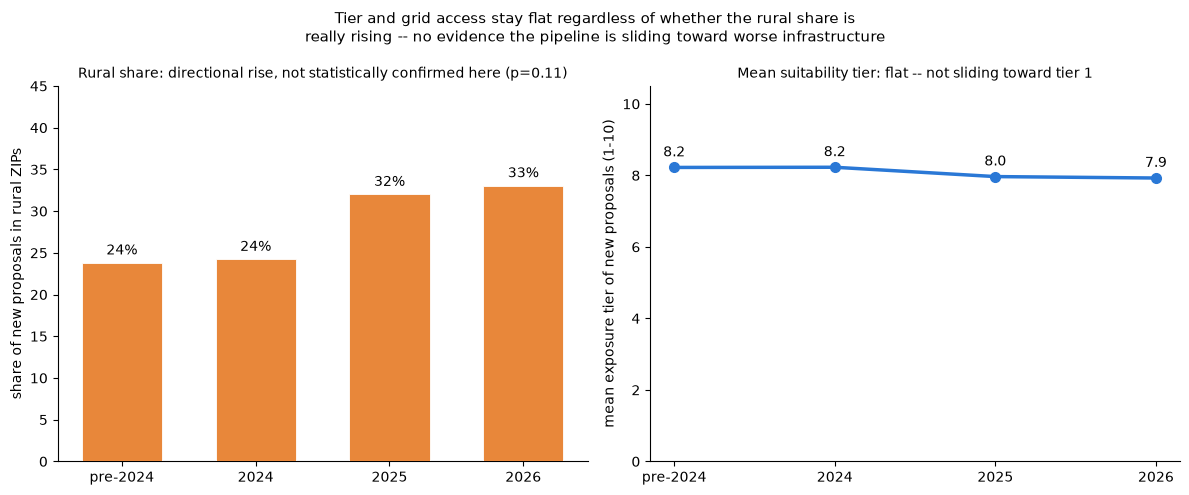

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
x = np.arange(len(period_df))

axes[0].bar(x, period_df["rural_share"] * 100, color="#e8873a", edgecolor="white",
            linewidth=0.6, zorder=3, width=0.6)
for xi, v in zip(x, period_df["rural_share"] * 100):
    axes[0].annotate(f"{v:.0f}%", (xi, v), xytext=(0, 6), textcoords="offset points",
                     ha="center", fontsize=10)
axes[0].set_ylabel("share of new proposals in rural ZIPs")
axes[0].set_ylim(0, 45)
axes[0].set_title("Rural share: directional rise, not statistically confirmed here (p=0.11)", fontsize=10)

axes[1].plot(x, period_df["mean_tier"], marker="o", ms=7, lw=2.5, color="#2a78d6")
for xi, v in zip(x, period_df["mean_tier"]):
    axes[1].annotate(f"{v:.1f}", (xi, v), xytext=(0, 8), textcoords="offset points",
                     ha="center", fontsize=10)
axes[1].set_ylabel("mean exposure tier of new proposals (1-10)")
axes[1].set_ylim(0, 10.5)
axes[1].set_title("Mean suitability tier: flat -- not sliding toward tier 1", fontsize=10)

for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(period_df["period"])
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

fig.suptitle("Tier and grid access stay flat regardless of whether the rural share is\n"
             "really rising -- no evidence the pipeline is sliding toward worse infrastructure",
             fontsize=11)
fig.tight_layout()
fig.savefig("dc_rural_tier_link.png", dpi=150, bbox_inches="tight")
plt.show()